# Assignment 7: Classification Analysis | Pair Assignment

**Goal:** build and compare a **Decision Tree** and a **Naive Bayes** classifier on your
group's dataset, then report what you found. EAch pair will choose one dataset from the following table and do the following.


Hints are provided in the cells marked `# TODO`. If you get stuck on syntax, check the code examples form this week.

> **Replace the loan_sample.cs with your chosen Kaggle dataset** and update the target column.

## Your dataset

| Group dataset | Example classification task | Target column | Kaggle link |
|---|---|---|---|
| SF Crime | Predict crime category, or district | `Category` / `PdDistrict` | https://www.kaggle.com/competitions/sf-crime/data
| NASA Asteroids | Predict if an asteroid is hazardous | `Hazardous` | https://www.kaggle.com/datasets/shrutimehta/nasa-asteroids-classification
| Hotel Booking | Predict if a booking is cancelled, or hotel type | `is_canceled` / `hotel` | https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

Use a Decision Tree for one task and Naive Bayes for the other (or, for Asteroids, run
both on the same task and compare). Keep notes as you go; you will need them for the report
at the bottom.

## Know your dataset before you start | Each pair will choose one of the following dataset

Read the block for your group's dataset first. It tells you what you are actually
predicting and the specific things to watch for at each step, so you are not surprised
halfway through.

### SF Crime, predicting crime category or district

**What you are figuring out:** can the time and place of an incident predict what kind of
crime it was, or which police district it happened in? You are turning raw incident logs
into useful predictors.

- **Exploration:** this file is huge (about 1 million rows). Take a random sample (say 50,000 rows) so your code runs fast. Check how many distinct crime categories exist.
- **Preprocessing:** the timestamp is not useful as text. Pull `hour`, `day of week`, and `month` out of it into their own numeric columns. If there are too many crime categories, group the rare ones into an "Other" bucket so the model is not splitting on dozens of tiny classes. Keep latitude and longitude; they are strong predictors.
- **Build models:** Decision Tree for one task (for example, category) and Naive Bayes for the other (district).
- **Evaluate:** with many classes, accuracy alone is thin. Look at the confusion matrix to see which categories get mixed up.


In [1]:
# Make native plotting libraries available when VS Code skips Conda activation.
import os
import sys
from pathlib import Path

_dll_handles = []
if os.name == "nt":
    library_bin = Path(sys.prefix) / "Library" / "bin"
    if library_bin.is_dir():
        os.environ["PATH"] = str(library_bin) + os.pathsep + os.environ.get("PATH", "")
        if hasattr(os, "add_dll_directory"):
            _dll_handles.append(os.add_dll_directory(str(library_bin)))

# Prerequisites
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("Ready.")

Ready.


## Step 1 - Data exploration

Load your data and get to know it: how many rows and columns, what the columns mean, and
how balanced the classes are. Class balance matters: if 90% of rows are one class, a model
can look accurate just by guessing that class every time.

In [2]:
# Look beside the notebook first, then in the original course folder.
data_path = Path("train.csv")
if not data_path.is_file():
    data_path = Path(r"C:\Users\TEpix\OneDrive\Documents\CSCI 3020\CSCI-4047-800\Mod07 Classification\Assignment\train.csv")
if not data_path.is_file():
    raise FileNotFoundError("Place train.csv in the same folder as this notebook.")
df = pd.read_csv(data_path)
target = "PdDistrict"
print("Dataset shape:", df.shape)
display(df.head(10))


Dataset shape: (878049, 9)


,Dates,Category,Descript,DayOfWeek,PdDistrict,Resolution,Address,X,Y
0,2015-05-13 23:53:00,WARRANTS,WARRANT ARREST,Wednesday,NORTHERN,"ARREST, BOOKED",OAK ST / LAGUNA ST,-122.425892,37.774599
1,2015-05-13 23:53:00,OTHER OFFENSES,TRAFFIC VIOLATION ARREST,Wednesday,NORTHERN,"ARREST, BOOKED",OAK ST / LAGUNA ST,-122.425892,37.774599
2,2015-05-13 23:33:00,OTHER OFFENSES,TRAFFIC VIOLATION ARREST,Wednesday,NORTHERN,"ARREST, BOOKED",VANNESS AV / GREENWICH ST,-122.424363,37.800414
3,2015-05-13 23:30:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,NORTHERN,NONE,1500 Block of LOMBARD ST,-122.426995,37.800873
4,2015-05-13 23:30:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,PARK,NONE,100 Block of BRODERICK ST,-122.438738,37.771541
5,2015-05-13 23:30:00,LARCENY/THEFT,GRAND THEFT FROM UNLOCKED AUTO,Wednesday,INGLESIDE,NONE,0 Block of TEDDY AV,-122.403252,37.713431
6,2015-05-13 23:30:00,VEHICLE THEFT,STOLEN AUTOMOBILE,Wednesday,INGLESIDE,NONE,AVALON AV / PERU AV,-122.423327,37.725138
7,2015-05-13 23:30:00,VEHICLE THEFT,STOLEN AUTOMOBILE,Wednesday,BAYVIEW,NONE,KIRKWOOD AV / DONAHUE ST,-122.371274,37.727564
8,2015-05-13 23:00:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,RICHMOND,NONE,600 Block of 47TH AV,-122.508194,37.776601
9,2015-05-13 23:00:00,LARCENY/THEFT,GRAND THEFT FROM LOCKED AUTO,Wednesday,CENTRAL,NONE,JEFFERSON ST / LEAVENWORTH ST,-122.419088,37.807802


In [3]:
# Explore the columns, numeric values, and police district balance.
df.info()
display(df.describe())
display(df[target].value_counts())


<class 'pandas.DataFrame'>
RangeIndex: 878049 entries, 0 to 878048
Data columns (total 9 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Dates       878049 non-null  str    
 1   Category    878049 non-null  str    
 2   Descript    878049 non-null  str    
 3   DayOfWeek   878049 non-null  str    
 4   PdDistrict  878049 non-null  str    
 5   Resolution  878049 non-null  str    
 6   Address     878049 non-null  str    
 7   X           878049 non-null  float64
 8   Y           878049 non-null  float64
dtypes: float64(2), str(7)
memory usage: 60.3 MB


,X,Y
count,878049.000000,878049.000000
mean,-122.422616,37.771020
std,0.030354,0.456893
min,-122.513642,37.707879
25%,-122.432952,37.752427
50%,-122.416420,37.775421
75%,-122.406959,37.784369
max,-120.500000,90.000000


PdDistrict
SOUTHERN      157182
MISSION       119908
NORTHERN      105296
BAYVIEW        89431
CENTRAL        85460
TENDERLOIN     81809
INGLESIDE      78845
TARAVAL        65596
PARK           49313
RICHMOND       45209
Name: count, dtype: int64

## Step 2 - Preprocessing

Get the data ready for the models. You will typically need to:

- Drop columns that are just identifiers or are not useful (e.g. an ID column).
- Handle missing values (fill numeric columns with the median, text columns with the mode).
- Encode categorical (text) columns into numbers with `pd.get_dummies(...)` or `LabelEncoder`.
- Separate the target `y` from the features `X`, then split into train and test sets.

In [4]:
# Check missing values and target counts.
display(df.isna().sum())
display(df[target].value_counts())


Dates         0
Category      0
Descript      0
DayOfWeek     0
PdDistrict    0
Resolution    0
Address       0
X             0
Y             0
dtype: int64

PdDistrict
SOUTHERN      157182
MISSION       119908
NORTHERN      105296
BAYVIEW        89431
CENTRAL        85460
TENDERLOIN     81809
INGLESIDE      78845
TARAVAL        65596
PARK           49313
RICHMOND       45209
Name: count, dtype: int64

In [5]:
# Keep the original 5,001-row subset without changing df.
print("Original shape:", df.shape)
data = df.head(5001).drop(columns=["Resolution", "Address", "Descript", "DayOfWeek"]).copy()
dates = pd.to_datetime(data["Dates"])
data["Hour"] = dates.dt.hour
data["Month"] = dates.dt.month
data["DayofYear"] = dates.dt.dayofyear
data = data.drop(columns=["Dates"])
print("Prepared shape:", data.shape)


Original shape: (878049, 9)
Prepared shape: (5001, 7)


C:\Users\esanc\AppData\Local\Temp\ipykernel_44412\869265975.py:7: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  data["DayofYear"] = dates.dt.dayofyear


In [6]:
# Encode predictors for police district prediction.
y = data[target]
features = data.drop(columns=[target])
X = pd.get_dummies(features, drop_first=True)
print("Target:", target)
print(list(X.columns))
display(X.head(10))


Target: PdDistrict
['X', 'Y', 'Hour', 'Month', 'DayofYear', 'Category_ASSAULT', 'Category_BRIBERY', 'Category_BURGLARY', 'Category_DISORDERLY CONDUCT', 'Category_DRIVING UNDER THE INFLUENCE', 'Category_DRUG/NARCOTIC', 'Category_DRUNKENNESS', 'Category_EMBEZZLEMENT', 'Category_FAMILY OFFENSES', 'Category_FORGERY/COUNTERFEITING', 'Category_FRAUD', 'Category_KIDNAPPING', 'Category_LARCENY/THEFT', 'Category_LIQUOR LAWS', 'Category_LOITERING', 'Category_MISSING PERSON', 'Category_NON-CRIMINAL', 'Category_OTHER OFFENSES', 'Category_PROSTITUTION', 'Category_ROBBERY', 'Category_RUNAWAY', 'Category_SECONDARY CODES', 'Category_SEX OFFENSES FORCIBLE', 'Category_STOLEN PROPERTY', 'Category_SUICIDE', 'Category_SUSPICIOUS OCC', 'Category_TRESPASS', 'Category_VANDALISM', 'Category_VEHICLE THEFT', 'Category_WARRANTS', 'Category_WEAPON LAWS']


,X,Y,Hour,Month,DayofYear,Category_ASSAULT,Category_BRIBERY,Category_BURGLARY,Category_DISORDERLY CONDUCT,Category_DRIVING UNDER THE INFLUENCE,...,Category_SECONDARY CODES,Category_SEX OFFENSES FORCIBLE,Category_STOLEN PROPERTY,Category_SUICIDE,Category_SUSPICIOUS OCC,Category_TRESPASS,Category_VANDALISM,Category_VEHICLE THEFT,Category_WARRANTS,Category_WEAPON LAWS
0,-122.425892,37.774599,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,-122.425892,37.774599,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,-122.424363,37.800414,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,-122.426995,37.800873,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,-122.438738,37.771541,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5,-122.403252,37.713431,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
6,-122.423327,37.725138,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
7,-122.371274,37.727564,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
8,-122.508194,37.776601,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9,-122.419088,37.807802,23,5,133,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [7]:
# Use the same stratified split for both models.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y
)
print("Training rows:", X_train.shape[0], "Test rows:", X_test.shape[0])


Training rows: 3750 Test rows: 1251


## Step 3 - Build the models

Each classifier is only a few lines: create it, then call `.fit(X_train, y_train)`.

In [8]:
# Train the Decision Tree on the shared split.
dtree = DecisionTreeClassifier(max_depth=5, random_state=1)
dtree.fit(X_train, y_train)
dt_predict = dtree.predict(X_test)
print("Decision Tree accuracy:", round(accuracy_score(y_test, dt_predict), 3))


Decision Tree accuracy: 0.9


In [9]:
# Train Naive Bayes on the same training and test rows.
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)
print("Naive Bayes accuracy:", round(accuracy_score(y_test, nb_pred), 3))


Naive Bayes accuracy: 0.239


## Step 4 - Evaluate and compare

For **each** model, predict on the test set and report:

- accuracy (`accuracy_score`)
- the confusion matrix (`ConfusionMatrixDisplay.from_predictions`)
- precision, recall, and F1 (`classification_report`)

Then compare: which model is more accurate, and what do the precision and recall for the
class you care about tell you?

In [10]:
# TODO: evaluate the Decision Tree
# Hint: dt_pred = dtree.predict(X_test)
#       print(accuracy_score(y_test, dt_pred))
#       ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues"); plt.show()
#       print(classification_report(y_test, dt_pred))

print("DECISION TREE EVALUATION")
print("Accuracy:", accuracy_score(y_test, dt_predict))
print(classification_report(y_test, dt_predict, zero_division=0))

DECISION TREE EVALUATION
Accuracy: 0.9000799360511591
              precision    recall  f1-score   support

     BAYVIEW       0.87      0.96      0.91       114
     CENTRAL       0.87      0.93      0.89       147
   INGLESIDE       0.93      0.93      0.93       107
     MISSION       0.96      0.87      0.92       149
    NORTHERN       0.84      0.91      0.87       162
        PARK       0.93      0.95      0.94        74
    RICHMOND       1.00      0.83      0.91        75
    SOUTHERN       0.91      0.85      0.88       225
     TARAVAL       1.00      0.96      0.98       113
  TENDERLOIN       0.76      0.84      0.80        85

    accuracy                           0.90      1251
   macro avg       0.91      0.90      0.90      1251
weighted avg       0.90      0.90      0.90      1251



Decision Tree Confusion Matrix:


,BAYVIEW,CENTRAL,INGLESIDE,MISSION,NORTHERN,PARK,RICHMOND,SOUTHERN,TARAVAL,TENDERLOIN
BAYVIEW,109,0,3,0,0,0,0,2,0,0
CENTRAL,0,136,0,0,3,0,0,1,0,7
INGLESIDE,5,0,100,2,0,0,0,0,0,0
MISSION,11,0,0,130,2,4,0,2,0,0
NORTHERN,0,5,0,1,148,0,0,2,0,6
PARK,0,0,1,2,1,70,0,0,0,0
RICHMOND,0,0,0,0,12,1,62,0,0,0
SOUTHERN,0,14,0,0,11,0,0,191,0,9
TARAVAL,0,0,4,0,0,0,0,0,109,0
TENDERLOIN,0,2,0,0,0,0,0,12,0,71


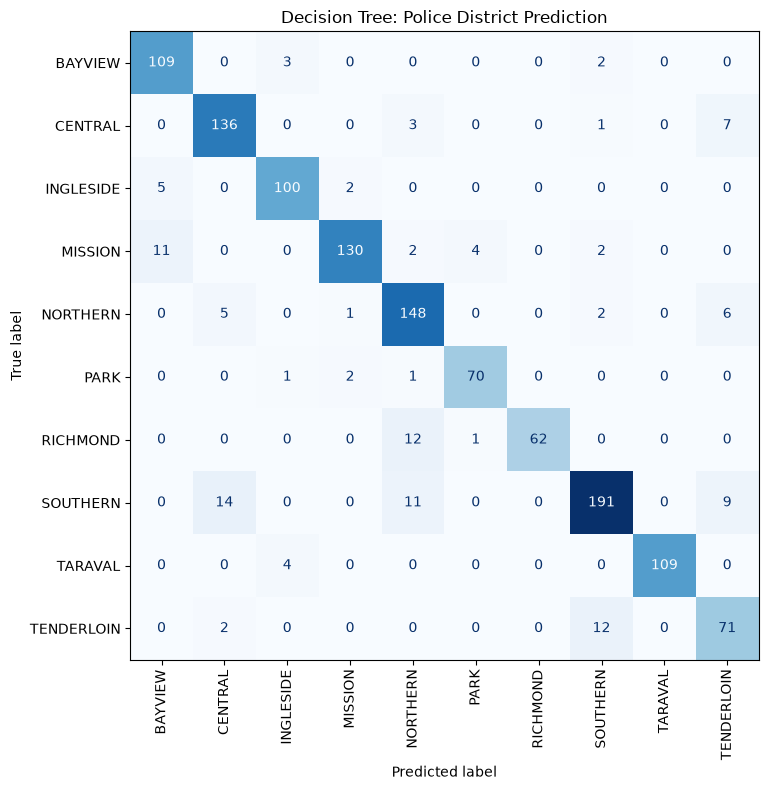

In [11]:
# Display the Decision Tree confusion matrix.
labels = dtree.classes_
matrix = confusion_matrix(y_test, dt_predict, labels=labels)
cm_df = pd.DataFrame(matrix, index=labels, columns=labels)
print("Decision Tree Confusion Matrix:")
display(cm_df)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(matrix, display_labels=labels).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False
)
ax.set_title("Decision Tree: Police District Prediction")
plt.tight_layout()
plt.show()


In [12]:
# TODO: evaluate the Naive Bayes model (same steps as above)

GaussianNB_pred = nb_model.predict(X_test)

print("NAIVE BAYES MODEL EVALUATION")
print("Accuracy:", accuracy_score(y_test, GaussianNB_pred))
print(classification_report(y_test, GaussianNB_pred, zero_division=0))

NAIVE BAYES MODEL EVALUATION
Accuracy: 0.2390087929656275
              precision    recall  f1-score   support

     BAYVIEW       0.90      0.64      0.75       114
     CENTRAL       0.81      0.12      0.20       147
   INGLESIDE       0.56      0.08      0.15       107
     MISSION       0.60      0.02      0.04       149
    NORTHERN       0.60      0.02      0.04       162
        PARK       0.08      0.96      0.14        74
    RICHMOND       0.21      0.04      0.07        75
    SOUTHERN       0.77      0.20      0.31       225
     TARAVAL       0.61      0.58      0.59       113
  TENDERLOIN       0.28      0.13      0.18        85

    accuracy                           0.24      1251
   macro avg       0.54      0.28      0.25      1251
weighted avg       0.61      0.24      0.25      1251



Naive Bayes Confusion Matrix:


,BAYVIEW,CENTRAL,INGLESIDE,MISSION,NORTHERN,PARK,RICHMOND,SOUTHERN,TARAVAL,TENDERLOIN
BAYVIEW,73,1,3,0,0,27,0,6,4,0
CENTRAL,1,17,0,0,0,120,0,6,0,3
INGLESIDE,1,0,9,0,1,68,0,1,27,0
MISSION,3,0,2,3,1,136,1,0,1,2
NORTHERN,0,2,1,1,3,151,1,0,1,2
PARK,0,0,0,1,0,71,2,0,0,0
RICHMOND,0,0,0,0,0,64,3,0,8,0
SOUTHERN,3,0,0,0,0,151,6,44,0,21
TARAVAL,0,0,1,0,0,47,0,0,65,0
TENDERLOIN,0,1,0,0,0,72,1,0,0,11


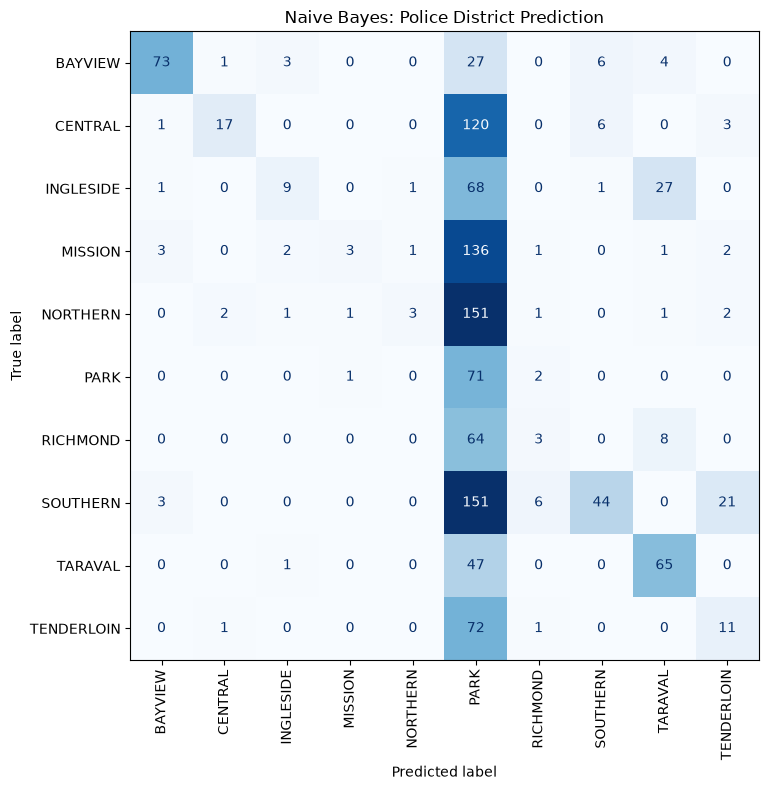

In [13]:
# Display the Naive Bayes confusion matrix.
labels = nb_model.classes_
matrix = confusion_matrix(y_test, GaussianNB_pred, labels=labels)
cm_df = pd.DataFrame(matrix, index=labels, columns=labels)
print("Naive Bayes Confusion Matrix:")
display(cm_df)
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(matrix, display_labels=labels).plot(
    ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False
)
ax.set_title("Naive Bayes: Police District Prediction")
plt.tight_layout()
plt.show()


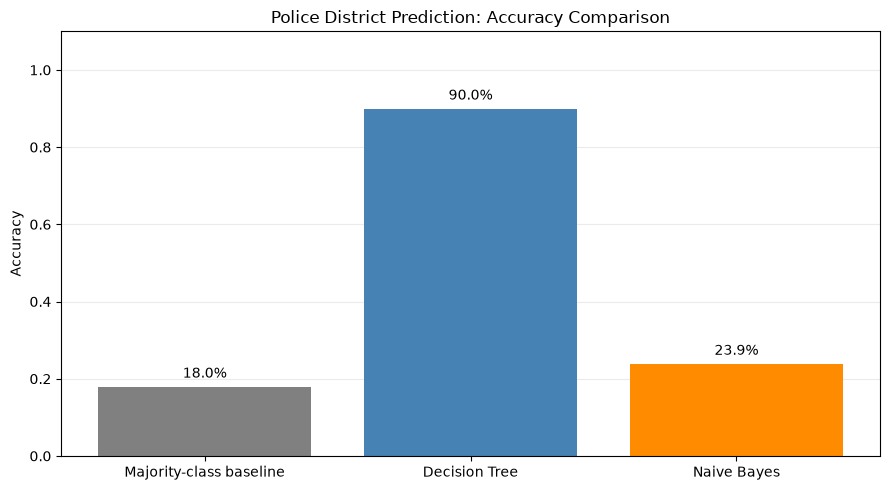

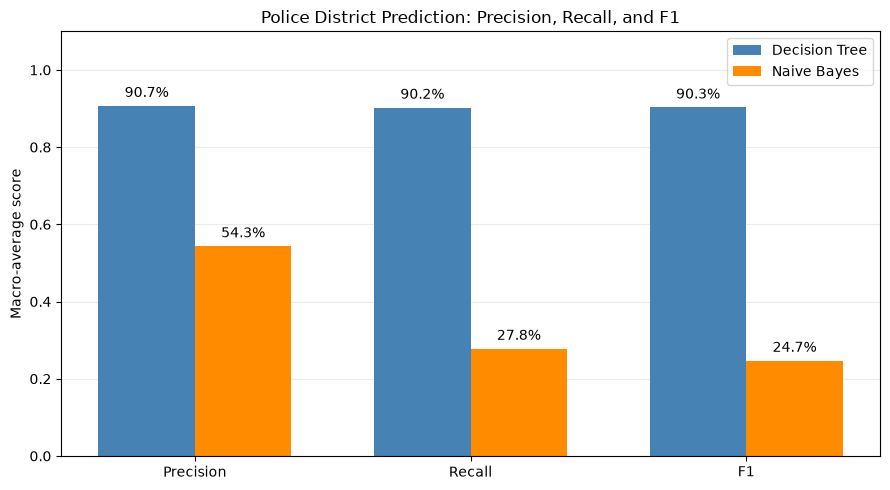

In [14]:
# Compare both models with a majority-class baseline
# Run the model-training cells above before running this cell.
dt_pred_graph = dtree.predict(X_test)
nb_pred_graph = nb_model.predict(X_test)

# Always predict the most common district in the training data.
majority_class = y_train.mode()[0]
baseline_accuracy = (y_test == majority_class).mean()

model_names = ["Majority-class baseline", "Decision Tree", "Naive Bayes"]
accuracies = [
    baseline_accuracy,
    accuracy_score(y_test, dt_pred_graph),
    accuracy_score(y_test, nb_pred_graph)
]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(model_names, accuracies, color=["gray", "steelblue", "darkorange"])
ax.set_title("Police District Prediction: Accuracy Comparison")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.1)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.bar_label(bars, labels=[f"{value:.1%}" for value in accuracies], padding=4)
ax.yaxis.grid(True, alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# Compare macro averages: each police district receives equal weight.
dt_report = classification_report(y_test, dt_pred_graph, output_dict=True, zero_division=0)
nb_report = classification_report(y_test, nb_pred_graph, output_dict=True, zero_division=0)
metrics = ["precision", "recall", "f1-score"]
positions = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
dt_bars = ax.bar(positions - width / 2,
                 [dt_report["macro avg"][m] for m in metrics],
                 width, label="Decision Tree", color="steelblue")
nb_bars = ax.bar(positions + width / 2,
                 [nb_report["macro avg"][m] for m in metrics],
                 width, label="Naive Bayes", color="darkorange")
ax.set_xticks(positions)
ax.set_xticklabels(["Precision", "Recall", "F1"])
ax.set_ylabel("Macro-average score")
ax.set_title("Police District Prediction: Precision, Recall, and F1")
ax.set_ylim(0, 1.1)
ax.set_yticks(np.arange(0, 1.01, 0.2))
for bars in [dt_bars, nb_bars]:
    ax.bar_label(bars, labels=[f"{bar.get_height():.1%}" for bar in bars], padding=4)
ax.legend()
ax.yaxis.grid(True, alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Step 5 - Findings

Write your answers here as you work.

1. **Preprocessing / data reduction** - what did you have to clean, drop, encode, or sample, and why?

   *Your answer:* This dataset was honestly very clean; we did not have to do much preprocessing. Because the data was large, what we did have to do was drop columns that contained unneccessary information. We dropped resolution, address, descript, and DayOfWeek columns. None of these were great predictors for what Category of crime was more likely or which District was more likley to have a crime commited. DayOfWeek was neccessary, but would require us to encode each day, when we could just pull that information from the date column after converting it to a datetime and also pulling the hour and year. We had to sample the rest of the data as they served as good predictors for PDistrict and Crime Category, but we did not use all ~1M data records, since again it would crash our computers. 


2. **Data used** - which features did you select as predictors, and why those?

   *Your answer:* We used longitude, latitude, crime category, Hour, Month, and DayofYear to predict police district. These features describe where and when incidents occurred and their type.

3. **Findings** - what did the analysis reveal about the data itself (patterns, surprises)?

   *Your answer:* One thing that surpised us was seeing how different the numbers came out in the decision tree vs the naive bayes model. The decision tree had a much better performance; we also did not expect for the data to be so accurate- after running the model and seeing the diagonals, we realized that the results were pretty good and rarely had incorrect data.  

4. **Decision Tree vs Naive Bayes** - which performed better on your task, and what are the
   strengths and shortcomings of each one here?

   *Your answer:* The Decision Tree performed better: 90.0% accuracy versus 23.9% for Naive Bayes. Trees can capture geographic boundaries but may overfit. Naive Bayes is fast, but its assumptions fit this dataset poorly.

5. **Challenges** - What was difficult, and how did you handle it?

   *Your answer:* The main challenge was the Jupyter kernel crashing when the notebook reached the graphs. The logs showed that VS Code was failing to activate the Conda environment correctly. We added setup code to make the environment’s required library folder available before importing the plotting libraries. We then tested the notebook in a fresh Jupyter kernel and it worked.

## Submission checklist

- This notebook (renamed `Last_First_Assignment7.ipynb`), with all cells run and output showing
- Link to your GitHub repository